In [1]:
import textwrap

import numpy as np
import pandas as pd
import xarray as xr

from matplotlib import pyplot as plt

In [2]:
ds_mean = xr.open_dataset("data/ensemble-mean.nc")
ds_spread = xr.open_dataset("data/ensemble-spread.nc")

In [3]:
def plot_ensemble_mean_spread(key, ax, sample=slice(None)):
    mean = ds_mean[key]
    spread = ds_spread[key]

    min_abs = float(spread.where(spread > 0.0).min(skipna=True))

    abs_mean = np.abs(mean)
    min_rel = spread.where(abs_mean > 0.0) / abs_mean.where(abs_mean > 0.0)
    min_rel = float(min_rel.where(min_rel > 0.0).min(skipna=True))

    months = sorted(set(zip(
        pd.to_datetime(ds_mean.tp.valid_time).year,
        pd.to_datetime(ds_mean.tp.valid_time).month,
    )))
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    ax.set_xlabel(f"mean [{mean.units}]")
    ax.set_ylabel(f"spread [{mean.units}]")

    if key in ("ssr", "tp"):
        ax.set_xscale("log")
        ax.set_yscale("log")

    handles = []

    for year, month in months:
        handles.append(ax.scatter(
            mean.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            spread.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            s=1, label=f"{year}/{month:02}", edgecolor="none", marker=".",
        ))

    legends = []

    legends.append(ax.axhline(min_abs, c="red", ls=":", label=f"abs = {min_abs:.03}"))

    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    rlim = sorted([xlim[0], 0.0, xlim[1]])

    legends.extend(ax.plot(rlim, np.array(rlim) * min_rel * np.sign(rlim), c="blue", ls=":", label=f"rel = {min_rel:.3%}"))

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
    ax.legend(handles=legends)

    return handles

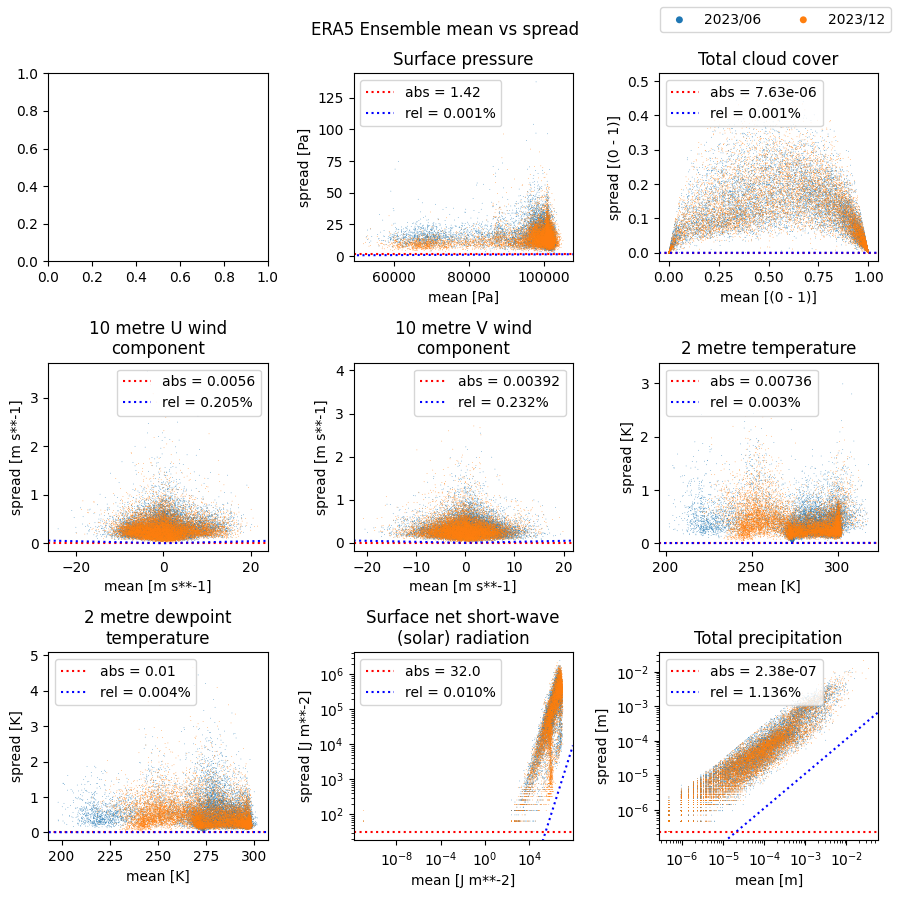

In [4]:
fig, axs = plt.subplots(3, 3, figsize=(9, 9))
fig.suptitle("ERA5 Ensemble mean vs spread")

for key, ax in zip(ds_mean, axs.flatten()):
    if key == "z":
        continue
    handles = plot_ensemble_mean_spread(key, ax, sample=slice(0, None, 5000))

fig.legend(handles=handles, loc="upper right", ncols=len(handles), markerscale=10)

fig.tight_layout()
plt.show()